## Convert the pb2002 plate model into a GPlates version



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pygplates


%matplotlib inline

# Data description based on Table 2 in the Bird (2003) Gcubed paper

pb2002 = pd.read_fwf('/Users/Simon/Data/GIS/BirdPlateBoundaries/PB2002_steps.dat',
                     header=0,
                     colspecs=[(0,4),(5,6),(6,11),(12,20),(21,28),(29,37),(38,45),(46,51),
                               (52,55),(56,61),(62,65),(66,72),(73,79),(80,86),(87,90),(91,92),(92,95),(95,96)],
                    names=('SequenceNum','Continuity1','PBID','LongStart','LatStart','LongEnd','LatEnd',
                           'Length','Azimuth','VelMag','VelAzim','DivVel','RightLatVel','Elev','SeafloorAge',
                           'Continuity2','StepClass','InOrogen'))
pb2002


/Users/Simon/anaconda/lib/python2.7/site-packages/pandas/computation/__init__.py:19: UserWarning: The installed version of numexpr 2.4.4 is not supported in pandas and will be not be used

  UserWarning)


,SequenceNum,Continuity1,PBID,LongStart,LatStart,LongEnd,LatEnd,Length,Azimuth,VelMag,VelAzim,DivVel,RightLatVel,Elev,SeafloorAge,Continuity2,StepClass,InOrogen
0,2,:,AF-AN,-0.039,-54.677,0.443,-54.451,40.0,51,13.2,47,0.9,13.1,-1639,5,:,OTF,NaN
1,3,:,AF-AN,0.443,-54.451,0.965,-54.832,54.0,142,13.2,47,13.1,-1.1,-1687,4,NaN,OSR,NaN
2,4,:,AF-AN,0.965,-54.832,1.695,-54.399,67.3,44,13.2,46,-0.4,13.2,-4289,1,NaN,OTF,NaN
3,5,:,AF-AN,1.695,-54.399,2.360,-54.037,59.0,47,13.2,45,0.4,13.2,-4517,2,:,OTF,NaN
4,6,:,AF-AN,2.360,-54.037,3.025,-53.651,61.3,45,13.2,45,0.2,13.2,-3845,7,:,OTF,NaN
5,7,:,AF-AN,3.025,-53.651,3.369,-53.834,30.4,132,13.2,44,13.2,0.5,-3964,5,NaN,OSR,NaN
6,8,:,AF-AN,3.369,-53.834,3.956,-54.127,50.3,130,13.2,44,13.2,0.8,-2073,0,:,OSR,NaN
7,9,:,AF-AN,3.956,-54.127,4.415,-54.430,45.0,139,13.3,43,13.2,-1.2,-2219,0,:,OSR,NaN
8,10,:,AF-AN,4.415,-54.430,4.827,-54.162,40.1,42,13.3,43,-0.2,13.3,-3360,1,NaN,OTF,NaN
9,11,:,AF-AN,4.827,-54.162,5.084,-54.309,23.4,135,13.3,42,13.3,-0.5,-3233,0,NaN,OSR,NaN


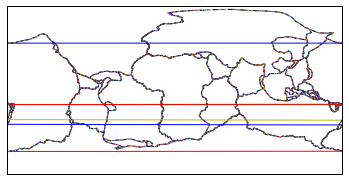

In [19]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

proj=ccrs.PlateCarree(180)
ax = plt.axes(projection=proj)
ax.set_global()

tmp = []
count=0
for index,row in pb2002.iterrows():
    ax.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],
            transform=proj)
    if pd.notnull(row.Continuity2):  
        count+=1
    tmp.append(count)
plt.show()


/Users/Simon/anaconda/lib/python2.7/site-packages/matplotlib/axes/_axes.py:519: UserWarning: No labelled objects found. Use label='...' kwarg on individual plots.
  warnings.warn("No labelled objects found. "


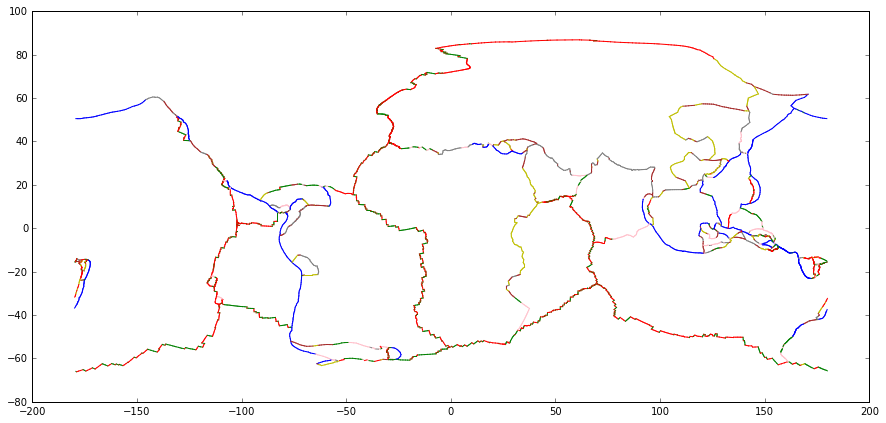

number of features is 468


In [7]:
from mpl_toolkits.basemap import Basemap

plt.figure(figsize=(15,7))
tmp = []
count=0
prevClass = ''
prevPBID = ''
for index,row in pb2002.iterrows():
    if np.abs(row.LongStart-row.LongEnd)<180:
        if row.StepClass=='CRB':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'y')
        elif row.StepClass=='CTF':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'brown')
        elif row.StepClass=='CCB':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'grey')
        elif row.StepClass=='OSR':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'r')
        elif row.StepClass=='OTF':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'g')
        elif row.StepClass=='OCB':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'pink')
        elif row.StepClass=='SUB':
            plt.plot([row.LongStart,row.LongEnd],[row.LatStart,row.LatEnd],'b')
    if ((prevClass=='CRB') | (prevClass=='CTF')) \
        & ((row.StepClass=='CRB') | (row.StepClass=='CTF')) \
        & (row.PBID==prevPBID):  
        count+=0
    elif ((prevClass=='OSR') | (prevClass=='OTF')) \
        & ((row.StepClass=='OSR') | (row.StepClass=='OTF')) \
        & (row.PBID==prevPBID):  
        count+=0
    elif ((prevClass=='CCB') | (prevClass=='OCB')) \
        & ((row.StepClass=='CCB') | (prevClass=='OCB')) \
        & (row.PBID==prevPBID):  
        count+=0 
    elif (prevClass=='SUB') & (row.StepClass=='SUB') \
        & (row.PBID==prevPBID): 
        count+=0
    else:
        count+=1
    tmp.append(count)
    prevClass = row.StepClass
    prevPBID = row.PBID

plt.show()

print 'number of features is %d' % tmp[-1]

pb2002['featureID'] = pd.Series(tmp,index=pb2002.index)


In [5]:
features = []

for index in np.arange(1,tmp[-1]):
    subset = pb2002.where(pb2002.featureID==index).dropna(axis=0,how='all')
    Longs = np.asarray(subset['LongStart'])
    Lats = np.asarray(subset['LatStart'])
    LongEnd = np.asarray(subset['LongEnd'])[-1]
    LatEnd = np.asarray(subset['LatEnd'])[-1]
    geom = pygplates.PolylineOnSphere(zip(np.hstack((Lats,LatEnd)),np.hstack((Longs,LongEnd))))
    
    if subset['StepClass'].iloc[0]=='SUB':
        feature_type = pygplates.FeatureType.gpml_subduction_zone
    elif subset['StepClass'].iloc[0]=='OSR':
        feature_type = pygplates.FeatureType.gpml_mid_ocean_ridge
    elif subset['StepClass'].iloc[0]=='OTF':
        feature_type = pygplates.FeatureType.gpml_mid_ocean_ridge
    elif subset['StepClass'].iloc[0]=='CTF':
        feature_type = pygplates.FeatureType.gpml_continental_rift
    elif subset['StepClass'].iloc[0]=='CRB':
        feature_type = pygplates.FeatureType.gpml_continental_rift
    elif subset['StepClass'].iloc[0]=='CCB':
        feature_type = pygplates.FeatureType.gpml_fault
    elif subset['StepClass'].iloc[0]=='OCB':
        feature_type = pygplates.FeatureType.gpml_fault
    
    subduction_zone_feature = pygplates.Feature.create_reconstructable_feature(
            feature_type,
            geom,
            name=subset['PBID'].iloc[0],
            valid_time=(5, pygplates.GeoTimeInstant.create_distant_future()))

    features.append(subduction_zone_feature)

feature_collection = pygplates.FeatureCollection(features)
feature_collection.write('pb2002.gpmlz')


In [6]:
# List of all plate pair combinations
plate_pair_list = pb2002.PBID.unique()

plate_list = []
for plate_pair in plate_pair_list:
    plate_list.append(plate_pair[0:2])
    plate_list.append(plate_pair[-2:])

# Get a list of unique plate ids
plate_list = pd.Series(plate_list).unique()
print plate_list

# For each unique plate
for plate in plate_list:
    # create an empty list to store boundary segments
    topology_list = []
    
    for feature in features:
        feature_name = feature.get_name()
        if plate in feature_name:
            topology_list.append(feature)
    
    topology_list
    


['AF' 'AN' 'SO' 'IN' 'AU' 'EU' 'NA' 'SA' 'NZ' 'PA' 'AR' 'SU' 'TI' 'KE' 'TO'
 'NI' 'WL' 'MO' 'SB' 'SS' 'NB' 'NH' 'CA' 'CO' 'OK' 'JF' 'AP' 'ND' 'ON' 'PS'
 'AM' 'CL' 'MA' 'FT' 'SC' 'SL' 'AS' 'AT' 'YA' 'BU' 'RI' 'BH' 'MS' 'BS' 'MN'
 'CR' 'BR' 'EA' 'JZ' 'GP' 'SW' 'PM']
